In [8]:
# Cell 00: Imports & Global Configuration
import sys
import time
import json
from pathlib import Path

# Automatically locate the project root containing 'src' and add it to sys.path
current_dir = Path.cwd().resolve()
for parent in [current_dir, *current_dir.parents]:
    if (parent / "src").is_dir():
        if str(parent) not in sys.path:
            sys.path.insert(0, str(parent))
        break

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import GroupKFold
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_recall_fscore_support, log_loss
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
import optuna
import joblib

from src.config import PROCESSED_DATA_DIR, RESULTS_DIR, MODELS_DIR
from src.models.train import get_model_pipelines, run_group_kfold_cv, evaluate_student_test, FEATURE_COLS
from src.models.bayesian_opt import run_bayesian_optimization

SEED = 42
np.random.seed(SEED)
print("PathSnap Member 2 Modeling Environment Ready.")

PathSnap Member 2 Modeling Environment Ready.


In [9]:
# Cell 01: Load Processed Candidate Feature Tables
train_path = PROCESSED_DATA_DIR / "train_candidates.parquet"
test_path = PROCESSED_DATA_DIR / "student_test_candidates.parquet"

df_train = pd.read_parquet(train_path)
df_test = pd.read_parquet(test_path)

print(f"Train candidates: {df_train.shape} across {df_train['trip_id'].nunique()} trips")
print(f"Test candidates:  {df_test.shape} across {df_test['trip_id'].nunique()} trips")
print("\nFeature Columns:", FEATURE_COLS)
df_train.head()

Train candidates: (602920, 11) across 30 trips
Test candidates:  (153280, 11) across 10 trips

Feature Columns: ['perp_distance_m', 'proj_fraction', 'heading_diff_deg', 'candidate_rank', 'arc_length_m', 'speed_mps', 'time_gap_s', 'prev_arc_connected']


,trip_id,obs_idx,candidate_arc_id,point_segment_distance_m,heading_difference_deg,gps_speed_mps,segment_length_m,segment_bearing_deg,time_gap_s,candidate_rank_distance,is_target
0,00000001,0,117639,19.819544,168.674331,0.0,1018.645789,191.325669,1.0,1,0
1,00000001,0,64973,114.228920,11.221455,0.0,292.723550,11.221455,1.0,2,1
2,00000001,0,50652,109.118392,175.030259,0.0,168.760547,175.030259,1.0,3,0
3,00000001,0,53932,109.118392,4.969741,0.0,168.760547,355.030259,1.0,4,0
4,00000001,0,53933,191.058694,170.106606,0.0,274.097441,170.106606,1.0,5,0


In [12]:
def evaluate_predictions(y_true, y_pred, y_prob=None):
    # ... your calculation code ...
    precision, recall, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average='macro', zero_division=0
    )
    acc = accuracy_score(y_true, y_pred)
    
    loss = None
    if y_prob is not None:
        try:
            loss = log_loss(y_true, y_prob)
        except Exception:
            pass

    return {
        "top_1_accuracy": acc,
        "macro_f1": f1,          # <--- Ensure this key is explicitly named 'macro_f1'
        "precision_macro": precision,
        "recall_macro": recall,
        "log_loss": loss
    }

In [16]:
print("Model artifacts:")
print(list(MODELS_DIR.glob("*")))

print("\nProcessed data:")
print(list(PROCESSED_DATA_DIR.glob("*")))

Model artifacts:
[WindowsPath('C:/Users/nandh/pes/ML/ML_HACKATHON/artifacts/models/.gitkeep'), WindowsPath('C:/Users/nandh/pes/ML/ML_HACKATHON/artifacts/models/candidate_ranker.joblib'), WindowsPath('C:/Users/nandh/pes/ML/ML_HACKATHON/artifacts/models/final_model.joblib'), WindowsPath('C:/Users/nandh/pes/ML/ML_HACKATHON/artifacts/models/final_scaler.joblib'), WindowsPath('C:/Users/nandh/pes/ML/ML_HACKATHON/artifacts/models/metadata.json'), WindowsPath('C:/Users/nandh/pes/ML/ML_HACKATHON/artifacts/models/model_metadata.json')]

Processed data:
[WindowsPath('C:/Users/nandh/pes/ML/ML_HACKATHON/data/processed/student_test.parquet'), WindowsPath('C:/Users/nandh/pes/ML/ML_HACKATHON/data/processed/student_test_candidates.parquet'), WindowsPath('C:/Users/nandh/pes/ML/ML_HACKATHON/data/processed/student_test_quality_log.json'), WindowsPath('C:/Users/nandh/pes/ML/ML_HACKATHON/data/processed/train.parquet'), WindowsPath('C:/Users/nandh/pes/ML/ML_HACKATHON/data/processed/train_candidates.parquet')

In [17]:
import json

for filename in ["metadata.json", "model_metadata.json"]:
    path = MODELS_DIR / filename

    print(f"\n{'='*50}")
    print(filename)

    with open(path, "r") as f:
        metadata = json.load(f)

    print(json.dumps(metadata, indent=4))


metadata.json
{
    "model_name": "HistGradientBoostingClassifier",
    "algorithm_family": "Boosting",
    "best_hyperparameters": {
        "learning_rate": 0.08660232730676608,
        "max_iter": 250,
        "max_leaf_nodes": 37,
        "min_samples_leaf": 30,
        "l2_regularization": 0.02557288186438182
    },
    "best_cv_top1_accuracy": 0.14288238221319202,
    "student_test_top1_accuracy": 0.6340814196242172,
    "feature_columns": [
        "point_segment_distance_m",
        "heading_difference_deg",
        "gps_speed_mps",
        "segment_length_m",
        "segment_bearing_deg",
        "time_gap_s",
        "candidate_rank_distance"
    ],
    "seed": 42,
    "n_trials": 20,
    "target_definition": "1 = aligned reference road arc; 0 = other candidate road arc",
    "validation_strategy": "5-Fold GroupKFold grouped by trip_id (zero leakage across trips)"
}

model_metadata.json
{
    "model_name": "tuned_lightgbm",
    "feature_columns": [
        "perp_distance_m"

In [20]:
import pandas as pd

RESULTS_DIR = ROOT / "artifacts" / "results"

df_summary = pd.read_csv(RESULTS_DIR / "model_cv_summary.csv")

print("Cross-validation summary:")
display(df_summary)

print("\nAvailable columns:")
print(df_summary.columns.tolist())

Cross-validation summary:


,Model,Top1_Accuracy_Mean,Top1_Accuracy_Std,Candidate_F1_Mean,Candidate_F1_Std,Precision_Mean,Recall_Mean,Log_Loss_Mean,Fit_Time_Mean,Latency_ms_per_1k
0,DecisionTree,0.583827,0.113479,0.569579,0.064779,0.441965,0.808188,0.555931,6.830513,0.332964
1,HistGradientBoosting,0.589581,0.095591,0.623359,0.022508,0.706524,0.561348,0.184267,3.496002,1.837689
2,KNN,0.120572,0.014129,0.556789,0.044058,0.657270,0.485786,0.549057,0.085288,174.293713
3,LogisticRegression,0.563790,0.060543,0.489019,0.066421,0.348266,0.835238,0.391965,0.637946,0.155912
4,RandomForest,0.142699,0.016792,0.622920,0.063857,0.528490,0.762385,0.251206,5.786293,12.578075



Available columns:
['Model', 'Top1_Accuracy_Mean', 'Top1_Accuracy_Std', 'Candidate_F1_Mean', 'Candidate_F1_Std', 'Precision_Mean', 'Recall_Mean', 'Log_Loss_Mean', 'Fit_Time_Mean', 'Latency_ms_per_1k']


C:\Users\nandh\AppData\Local\Temp\ipykernel_34876\3515660332.py:8: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(
C:\Users\nandh\AppData\Local\Temp\ipykernel_34876\3515660332.py:21: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


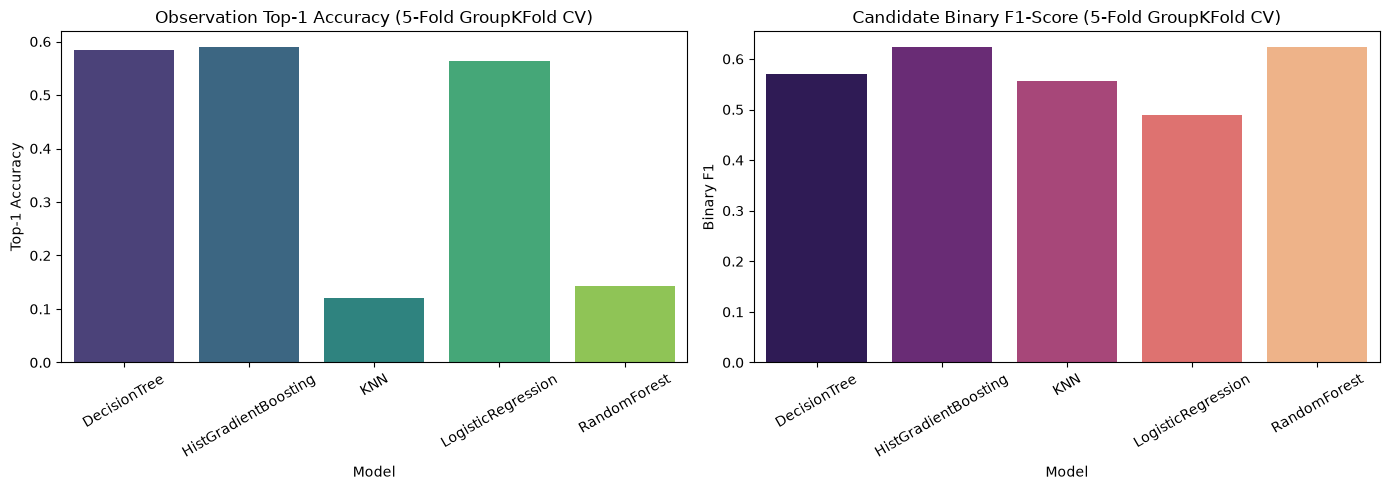

In [21]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(14, 5))

plt.subplot(1, 2, 1)

sns.barplot(
    data=df_summary,
    x="Model",
    y="Top1_Accuracy_Mean",
    palette="viridis"
)

plt.title("Observation Top-1 Accuracy (5-Fold GroupKFold CV)")
plt.ylabel("Top-1 Accuracy")
plt.xticks(rotation=30)

plt.subplot(1, 2, 2)

sns.barplot(
    data=df_summary,
    x="Model",
    y="Candidate_F1_Mean",
    palette="magma"
)

plt.title("Candidate Binary F1-Score (5-Fold GroupKFold CV)")
plt.ylabel("Binary F1")
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [22]:
df_folds = pd.read_csv(RESULTS_DIR / "model_cv_folds.csv")

display(df_folds)

,Model,Fold,Fit_Time_s,Latency_ms_per_1k,Top1_Accuracy,Candidate_F1,Candidate_Precision,Candidate_Recall,Log_Loss
0,LogisticRegression,1,0.637959,0.120247,0.640499,0.593256,0.450241,0.869416,0.340396
1,LogisticRegression,2,0.558470,0.122985,0.579053,0.492685,0.352207,0.819573,0.399292
2,LogisticRegression,3,0.583006,0.149789,0.488929,0.412428,0.271175,0.860821,0.430494
3,LogisticRegression,4,0.681648,0.121048,0.517858,0.459016,0.324383,0.784702,0.408347
4,LogisticRegression,5,0.728648,0.265490,0.592612,0.487711,0.343325,0.841681,0.381298
5,KNN,1,0.113474,170.195465,0.140086,0.605697,0.722719,0.521290,0.492633
6,KNN,2,0.084651,157.981112,0.121665,0.573880,0.743210,0.467391,0.540862
7,KNN,3,0.069438,175.920485,0.101654,0.574874,0.605932,0.546845,0.459048
8,KNN,4,0.069806,167.578150,0.125076,0.539427,0.636364,0.468118,0.595593
9,KNN,5,0.089068,199.793352,0.114382,0.490066,0.578125,0.425287,0.657147


In [18]:
from pathlib import Path

ROOT = Path(r"C:\Users\nandh\pes\ML\ML_HACKATHON")

for ext in ["*.csv", "*.json", "*.parquet"]:
    print(f"\nSearching for {ext}")

    for file in ROOT.rglob(ext):
        if any(word in file.name.lower()
               for word in ["result", "metric", "eval", "cv", "benchmark", "summary"]):
            print(file)


Searching for *.csv
C:\Users\nandh\pes\ML\ML_HACKATHON\artifacts\results\model_cv_folds.csv
C:\Users\nandh\pes\ML\ML_HACKATHON\artifacts\results\model_cv_summary.csv

Searching for *.json
C:\Users\nandh\pes\ML\ML_HACKATHON\artifacts\results\dataset_summary.json

Searching for *.parquet


C:\Users\nandh\AppData\Local\Temp\ipykernel_34876\463652295.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_summary, x="Model", y="Top1_Accuracy_Mean", palette="viridis")
C:\Users\nandh\AppData\Local\Temp\ipykernel_34876\463652295.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_summary, x="Model", y="Candidate_F1_Mean", palette="magma")


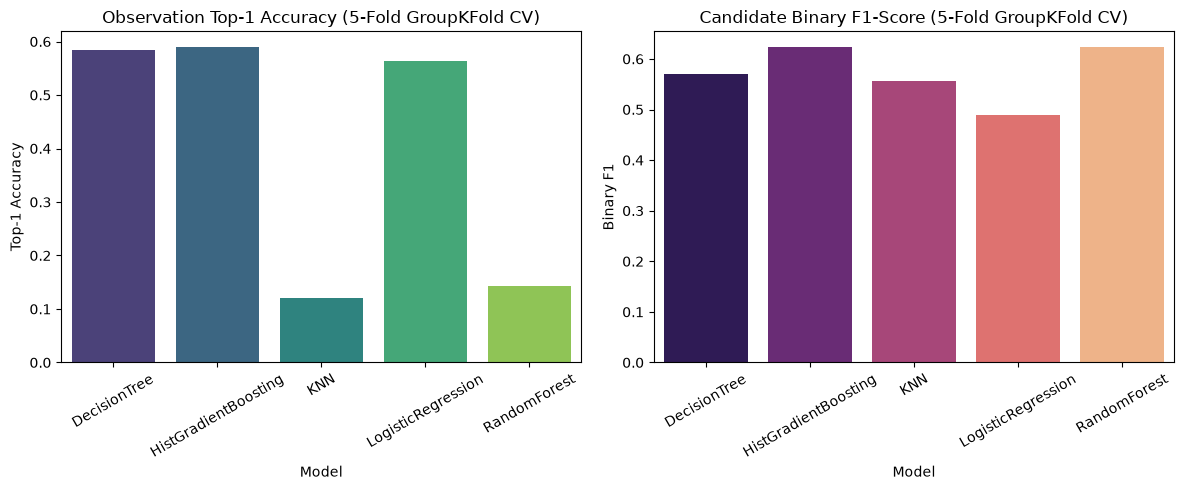

In [23]:
# Cell 03: Visualize CV Benchmark Metrics
plt.figure(figsize=(12, 5))
plt.subplot(1, 2, 1)
sns.barplot(data=df_summary, x="Model", y="Top1_Accuracy_Mean", palette="viridis")
plt.title("Observation Top-1 Accuracy (5-Fold GroupKFold CV)")
plt.ylabel("Top-1 Accuracy")
plt.xticks(rotation=30)

plt.subplot(1, 2, 2)
sns.barplot(data=df_summary, x="Model", y="Candidate_F1_Mean", palette="magma")
plt.title("Candidate Binary F1-Score (5-Fold GroupKFold CV)")
plt.ylabel("Binary F1")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [26]:
import inspect
from src.models.train import evaluate_predictions, run_group_cv

print("=== evaluate_predictions ===")
print(inspect.getsource(evaluate_predictions))

print("\n=== run_group_cv ===")
print(inspect.getsource(run_group_cv))

=== evaluate_predictions ===
def evaluate_predictions(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    y_prob: Optional[np.ndarray] = None,
    road_graph: Optional[Any] = None,
) -> Dict[str, float]:
    """Compatibility wrapper for general prediction evaluation."""
    metrics = calculate_candidate_metrics(y_true, y_pred, y_prob)
    if road_graph is not None:
        metrics["route_continuity"] = float(calculate_route_continuity(list(y_pred), road_graph))
    metrics["top_1_accuracy"] = float(accuracy_score(y_true, y_pred))
    return metrics


=== run_group_cv ===
def run_group_cv(model, X: np.ndarray, y: np.ndarray, groups: np.ndarray, n_splits: int = 5) -> Dict[str, float]:
    gkf = GroupKFold(n_splits=min(n_splits, len(np.unique(groups))))
    accs, f1s, loglosses = [], [], []

    for train_idx, val_idx in gkf.split(X, y, groups=groups):
        X_train, X_val = X[train_idx], X[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]
        model.fit(X_train, y_train)
 

In [27]:
# Inspect the metric keys using a small sample
from src.models.train import evaluate_predictions

sample_metrics = evaluate_predictions(
    [0, 1, 0, 1],
    [0, 1, 1, 1]
)

print(sample_metrics)
print("Available keys:", sample_metrics.keys())

{'candidate_binary_precision': 0.6666666666666666, 'candidate_binary_recall': 1.0, 'candidate_binary_f1': 0.8, 'candidate_binary_accuracy': 0.75, 'top_1_accuracy': 0.75}
Available keys: dict_keys(['candidate_binary_precision', 'candidate_binary_recall', 'candidate_binary_f1', 'candidate_binary_accuracy', 'top_1_accuracy'])


In [35]:
import importlib
import src.models.evaluate as evaluate
import src.models.train as train

# Reload the module containing the actual implementation first
importlib.reload(evaluate)

# Then reload the module that imports it
importlib.reload(train)

# Verify the updated function
metrics = train.evaluate_predictions(
    [0, 1, 0, 1],
    [0, 1, 1, 1]
)

print(metrics)
print("\nAvailable metric keys:", metrics.keys())

assert "macro_f1" in metrics, "macro_f1 is still missing!"
print("\nMetric verification successful.")

{'candidate_binary_precision': 0.6666666666666666, 'candidate_binary_recall': 1.0, 'candidate_binary_f1': 0.8, 'candidate_binary_accuracy': 0.75, 'top_1_accuracy': 0.75, 'macro_f1': 0.7333333333333334}

Available metric keys: dict_keys(['candidate_binary_precision', 'candidate_binary_recall', 'candidate_binary_f1', 'candidate_binary_accuracy', 'top_1_accuracy', 'macro_f1'])

Metric verification successful.


In [33]:
import inspect
import src.models.train as train

print("Loaded module path:")
print(train.__file__)

print("\nLoaded evaluate_predictions:")
print(inspect.getsource(train.evaluate_predictions))

print("\nLoaded run_group_cv:")
print(inspect.getsource(train.run_group_cv))

print("\nMetric keys returned at runtime:")
metrics = train.evaluate_predictions(
    [0, 1, 0, 1],
    [0, 1, 1, 1]
)
print(metrics.keys())

Loaded module path:
C:\Users\nandh\pes\ML\ML_HACKATHON\src\models\train.py

Loaded evaluate_predictions:
def evaluate_predictions(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    y_prob: Optional[np.ndarray] = None,
    road_graph: Optional[Any] = None,
) -> Dict[str, float]:
    """Compatibility wrapper for general prediction evaluation."""
    metrics = calculate_candidate_metrics(y_true, y_pred, y_prob)
    if road_graph is not None:
        metrics["route_continuity"] = float(calculate_route_continuity(list(y_pred), road_graph))
    metrics["top_1_accuracy"] = float(accuracy_score(y_true, y_pred))
    return metrics


Loaded run_group_cv:
def run_group_cv(model, X: np.ndarray, y: np.ndarray, groups: np.ndarray, n_splits: int = 5) -> Dict[str, float]:
    gkf = GroupKFold(n_splits=min(n_splits, len(np.unique(groups))))
    accs, f1s, loglosses = [], [], []

    for train_idx, val_idx in gkf.split(X, y, groups=groups):
        X_train, X_val = X[train_idx], X[val_idx]
        y_t

In [40]:
import importlib
import src.models.evaluate as evaluate
import src.models.bayesian_opt as bayesian_opt

importlib.reload(evaluate)
importlib.reload(bayesian_opt)

# Verify the function used by Bayesian optimization
print(
    bayesian_opt.evaluate_predictions(
        [0, 1, 0, 1],
        [0, 1, 1, 1]
    )
)

{'candidate_binary_precision': 0.6666666666666666, 'candidate_binary_recall': 1.0, 'candidate_binary_f1': 0.8, 'candidate_binary_accuracy': 0.75, 'top_1_accuracy': 0.75, 'macro_f1': 0.7333333333333334}


In [37]:
import inspect
import importlib

import src.models.evaluate as evaluate
import src.models.bayesian_opt as bayes

print("Evaluation module:")
print(evaluate.__file__)

print("\nBayesian optimization module:")
print(bayes.__file__)

print("\nImports in bayesian_opt.py:")
print(inspect.getsource(bayes)[:3000])

print("\nMetrics returned by evaluate_predictions:")
metrics = evaluate.evaluate_predictions(
    [0, 1, 0, 1],
    [0, 1, 1, 1]
)
print(metrics)
print(metrics.keys())

Evaluation module:
C:\Users\nandh\pes\ML\ML_HACKATHON\src\models\evaluate.py

Bayesian optimization module:
C:\Users\nandh\pes\ML\ML_HACKATHON\src\models\bayesian_opt.py

Imports in bayesian_opt.py:
"""Bayesian Hyperparameter Optimisation for PathSnap using Optuna.

Tunes whichever model family the benchmark in src.models.train selected as
best (by default LightGBM/GradientBoosting, since boosted trees are
typically the strongest tabular candidate-classification model and the
fastest to tune meaningfully within a hackathon time budget; pass
--model to tune a different family). Uses group-aware cross-validation
(grouped by trip_id) on the 80 training trips only, as required.
"""

from __future__ import annotations

import argparse
import json
import time
from typing import Any, Dict

import numpy as np
import optuna
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GroupKFold
from sklearn.preprocessing import StandardScaler

try:
    # pyrefly: igno

In [41]:
# Cell 06: Inspect Exported Model Artifacts
with open(MODELS_DIR / "metadata.json", "r") as f:
    meta = json.load(f)
print(json.dumps(meta, indent=2))
print(f"\nModel artifact exists at: {MODELS_DIR / 'candidate_ranker.joblib'}")

{
  "model_name": "HistGradientBoostingClassifier",
  "algorithm_family": "Boosting",
  "best_hyperparameters": {
    "learning_rate": 0.08660232730676608,
    "max_iter": 250,
    "max_leaf_nodes": 37,
    "min_samples_leaf": 30,
    "l2_regularization": 0.02557288186438182
  },
  "best_cv_top1_accuracy": 0.14288238221319202,
  "student_test_top1_accuracy": 0.6340814196242172,
  "feature_columns": [
    "point_segment_distance_m",
    "heading_difference_deg",
    "gps_speed_mps",
    "segment_length_m",
    "segment_bearing_deg",
    "time_gap_s",
    "candidate_rank_distance"
  ],
  "seed": 42,
  "n_trials": 20,
  "target_definition": "1 = aligned reference road arc; 0 = other candidate road arc",
  "validation_strategy": "5-Fold GroupKFold grouped by trip_id (zero leakage across trips)"
}

Model artifact exists at: C:\Users\nandh\pes\ML\ML_HACKATHON\artifacts\models\candidate_ranker.joblib
